# Системы поддержки принятия решений

**Тема: «Упражнения 2.1–2.10»**

Источник: Васильев Н. В. *Системы и методы поддержки принятия решений*. СПбГЭТУ «ЛЭТИ», 2026. Условия упражнений — с. 93–97. Использованы приёмы линеаризации абсолютных величин (с. 62–65), минимаксной цели (с. 72–73), дробной цели (с. 74–77) и линейной двойственности (с. 78–85).

**Оглавление**

| Задача | Содержание | Задача | Содержание |
|:---|:---|:---|:---|
| [2.1](#task-21) | Комплекты товаров и двойственность | [2.6](#task-26) | Выпуск двух продуктов |
| [2.2](#task-22) | Производство столов и стульев | [2.7](#task-27) | Ускорение проекта |
| [2.3](#task-23) | Распределение посевных площадей | [2.8](#task-28) | Сроки доставки |
| [2.4](#task-24) | Назначение рабочих на машины | [2.9](#task-29) | Абсолютные величины |
| [2.5](#task-25) | Инвестиционный портфель | [2.10](#task-210) | Дробная целевая функция |

Среда: Python, Pyomo и HiGHS. Перед просмотром результатов следует выполнить **Kernel → Restart Kernel and Run All Cells**. Для задачи 2.2 использовано дополнение к исходным данным: 5 досковых футов на стул и 15 — на стол. В задаче 2.8 исходные величины заданы символически, поэтому решение представлено параметрическими моделями.

In [1]:
import pyomo.environ as pyo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 10)

plt.rcParams.update({
    "figure.figsize": (8.5, 5.2),
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "lines.linewidth": 2,
    "savefig.bbox": "tight",
})

solver = None
for solver_name in ("appsi_highs", "highs", "cbc"):
    candidate = pyo.SolverFactory(solver_name)
    if candidate.available(exception_flag=False):
        solver = candidate
        break

if solver is None:
    raise RuntimeError(
        "Решатель не найден. Установите highspy: python -m pip install highspy"
    )

def solve_model(model):
    result = solver.solve(model, tee=False)
    pyo.assert_optimal_termination(result)
    return result

print(f"Решатель: {solver_name}. Среда готова к выполнению задач.")

Решатель: appsi_highs. Среда готова к выполнению задач.


<a id="task-21"></a>

## Задача 2.1

### Условие

Менеджер магазина смартфонов стремится реализовать имеющиеся запасы в связи с появлением новых моделей. В наличии имеется 8 телефонов, 4 комплекта гарнитур и 19 предоплаченных карт. Согласно результатам маркетингового исследования, менеджер может сформировать два вида комплектов:

- комплект из телефона и двух предоплаченных карт, приносящий прибыль $\text{\$7}$;
- комплект из телефона, гарнитуры и трёх предоплаченных карт, приносящий прибыль $\text{\$9}$.

Предполагается, что любое количество комплектов обоих видов может быть реализовано при условии наличия соответствующих товаров.

(a) Сформулируйте задачу линейного программирования, определяющую количество комплектов каждого вида, которое следует подготовить для максимизации прибыли. Найдите оптимальное решение.

(b) Торговый представитель сети супермаркетов предлагает выкупить товарные запасы магазина по отдельным позициям, а не сформированными комплектами. Определите минимальные удельные цены на телефон, гарнитуру и предоплаченную карту, которые обеспечили бы менеджеру не меньшую прибыль, чем самостоятельная реализация комплектов.

(c) Какова взаимосвязь между моделями, построенными в пунктах (a) и (b)?

(d) Как следует оценить предложение супермаркета о выкупе всего товарного запаса по цене:

- $\text{\$65}$;
- $\text{\$62}$;
- $\text{\$60}$?

### Дано

- Запас: 8 телефонов, 4 гарнитуры и 19 предоплаченных карт.
- Комплект 1: 1 телефон и 2 карты; прибыль — 7 долл./комплект.
- Комплект 2: 1 телефон, 1 гарнитура и 3 карты; прибыль — 9 долл./комплект.
- Предложения за весь запас: 65, 62 и 60 долл.
- Сбыт ограничен только наличием товаров.

### Математическая модель

**(a) Прямая задача.** Пусть $x_1,x_2$ — количество комплектов первого и второго вида. По требованию условия строится ЛП с непрерывными переменными; найденный оптимум проверяется на целочисленность.

$$
\begin{aligned}
\max\quad &P=7x_1+9x_2,\\
\text{при}\quad &x_1+x_2\le8,\\
&x_2\le4,\\
&2x_1+3x_2\le19,\\
&x_1,x_2\ge0.
\end{aligned}
$$

**(b) Двойственная задача.** Пусть $u,v,w\ge0$ — удельные оценки телефона, гарнитуры и карты, долл./шт. Стоимость товаров в каждом комплекте должна покрывать прибыль от его самостоятельной продажи. Минимизируется стоимость всего имеющегося запаса:

$$
\begin{aligned}
\min\quad &D=8u+4v+19w,\\
\text{при}\quad &u+2w\ge7,\\
&u+v+3w\ge9,\\
&u,v,w\ge0.
\end{aligned}
$$

Минимальные удельные цены здесь понимаются как согласованный набор оценок, минимизирующий стоимость всего запаса при указанных ограничениях.

**(c)** Модели образуют прямую и двойственную пару. По слабой двойственности $P\le D$ для любых допустимых решений; в оптимуме $P^*=D^*$. Условия дополняющей нежёсткости имеют вид

$$
\begin{gathered}
u(8-x_1-x_2)=0,\quad v(4-x_2)=0,\quad
w(19-2x_1-3x_2)=0,\\
x_1(u+2w-7)=0,\quad x_2(u+v+3w-9)=0.
\end{gathered}
$$

**(d)** Предложение $S$ сравнивается с $P^*$: разность $S-P^*$ показывает изменение прибыли при продаже всего запаса.

### Найти

(a) Постановку ЛП и оптимальное количество комплектов каждого вида.  
(b) Минимальные удельные цены на телефон, гарнитуру и карту.  
(c) Взаимосвязь построенных моделей.  
(d) Оценку предложений 65, 62 и 60 долл. за весь запас.

### Решение

In [2]:
model_21 = pyo.ConcreteModel()
model_21.first_bundle = pyo.Var(domain=pyo.NonNegativeReals)
model_21.second_bundle = pyo.Var(domain=pyo.NonNegativeReals)
model_21.phone_limit = pyo.Constraint(
    expr=model_21.first_bundle + model_21.second_bundle <= 8
)
model_21.headset_limit = pyo.Constraint(expr=model_21.second_bundle <= 4)
model_21.card_limit = pyo.Constraint(
    expr=2 * model_21.first_bundle + 3 * model_21.second_bundle <= 19
)
model_21.profit = pyo.Objective(
    expr=7 * model_21.first_bundle + 9 * model_21.second_bundle,
    sense=pyo.maximize,
)
solve_model(model_21)

bundle_values = np.array([
    pyo.value(model_21.first_bundle),
    pyo.value(model_21.second_bundle),
])
profit_21 = pyo.value(model_21.profit)
display(pd.DataFrame({
    "Комплект": ["Первый", "Второй"],
    "Количество, шт.": bundle_values,
}))
print(f"Максимальная прибыль: {profit_21:.2f} долл.")
print(f"Оптимум целочисленный: {np.allclose(bundle_values, np.round(bundle_values))}")

,Комплект,"Количество, шт."
0,Первый,5.0000
1,Второй,3.0000


Максимальная прибыль: 62.00 долл.
Оптимум целочисленный: True


In [3]:
dual_21 = pyo.ConcreteModel()
dual_21.phone_price = pyo.Var(domain=pyo.NonNegativeReals)
dual_21.headset_price = pyo.Var(domain=pyo.NonNegativeReals)
dual_21.card_price = pyo.Var(domain=pyo.NonNegativeReals)
dual_21.first_bundle_value = pyo.Constraint(
    expr=dual_21.phone_price + 2 * dual_21.card_price >= 7
)
dual_21.second_bundle_value = pyo.Constraint(
    expr=dual_21.phone_price + dual_21.headset_price + 3 * dual_21.card_price >= 9
)
dual_21.stock_value = pyo.Objective(
    expr=8 * dual_21.phone_price + 4 * dual_21.headset_price + 19 * dual_21.card_price,
    sense=pyo.minimize,
)
solve_model(dual_21)

resource_prices = np.array([
    pyo.value(dual_21.phone_price),
    pyo.value(dual_21.headset_price),
    pyo.value(dual_21.card_price),
])
resource_use = np.array([[1, 1], [0, 1], [2, 3]]) @ bundle_values
display(pd.DataFrame({
    "Товар": ["Телефон", "Гарнитура", "Карта"],
    "Запас, шт.": [8, 4, 19],
    "Использовано, шт.": resource_use,
    "Остаток, шт.": np.array([8, 4, 19]) - resource_use,
    "Двойственная оценка, долл./шт.": resource_prices,
}))
print(f"Минимальная стоимость запаса: {pyo.value(dual_21.stock_value):.2f} долл.")
print(f"Разрыв двойственности: {pyo.value(dual_21.stock_value) - profit_21:.2e}")

offers = np.array([65, 62, 60])
display(pd.DataFrame({
    "Предложение, долл.": offers,
    "Изменение прибыли, долл.": offers - profit_21,
    "Оценка": ["Выгодно принять", "Равноценно", "Невыгодно принимать"],
}))

,Товар,"Запас, шт.","Использовано, шт.","Остаток, шт.","Двойственная оценка, долл./шт."
0,Телефон,8,8.0000,0.0000,3.0000
1,Гарнитура,4,3.0000,1.0000,0.0000
2,Карта,19,19.0000,0.0000,2.0000


Минимальная стоимость запаса: 62.00 долл.
Разрыв двойственности: 0.00e+00


,"Предложение, долл.","Изменение прибыли, долл.",Оценка
0,65,3.0000,Выгодно принять
1,62,0.0000,Равноценно
2,60,-2.0000,Невыгодно принимать


### Ответ

**(a)** ЛП: $\max(7x_1+9x_2)$ при $x_1+x_2\le8$, $x_2\le4$, $2x_1+3x_2\le19$, $x_1,x_2\ge0$. Оптимально подготовить **5 комплектов первого вида и 3 комплекта второго вида**; максимальная прибыль — **62 долл.**

**(b)** Минимальные удельные оценки: **3 долл. за телефон, 0 долл. за гарнитуру и 2 долл. за карту**. Стоимость всего запаса равна $8\cdot3+4\cdot0+19\cdot2=62$ долл. Нулевая оценка гарнитуры означает отсутствие её дефицита в оптимальном плане, а не нулевую рыночную стоимость.

**(c)** Модель (b) двойственна модели (a); оптимальные значения совпадают и равны 62 долл. Двойственные переменные являются теневыми ценами соответствующих ограничений на запасы.

**(d)** За **65 долл.** запас выгодно продать: прибыль выше на 3 долл.; **62 долл.** равноценны самостоятельной продаже комплектов; предложение **60 долл.** невыгодно: прибыль ниже на 2 долл.

<a id="task-22"></a>

## Задача 2.2

### Условие

Компания Furnco производит столы и стулья, используя древесину и трудовые ресурсы. Стоимость древесины составляет $\text{\$1}$ за досковый фут, а её доступный объём равен 40000 досковых футов. Изготовление незавершённого стола или стула требует 2 часов труда; для их отделки необходимо дополнительно соответственно 3 и 2 часа. Общий фонд рабочего времени составляет 6000 часов. Незавершённые и готовые столы продаются соответственно по $\text{\$70}$ и $\text{\$140}$, а стулья — по $\text{\$60}$ и $\text{\$110}$. Сформулируйте задачу линейного программирования для максимизации прибыли от производства столов и стульев.

**Дополнение к исходным данным:** расход древесины на один стул составляет 5 досковых футов, на один стол — 15 досковых футов.

### Дано

- Стол: расход древесины **15 доск. фут/шт.**; изготовление — **2 ч/шт.**, отделка — ещё **3 ч/шт.**; цена незавершённого изделия — **70 долл.**, готового — **140 долл.**
- Стул: расход древесины **5 доск. фут/шт.**; изготовление — **2 ч/шт.**, отделка — ещё **2 ч/шт.**; цена незавершённого изделия — **60 долл.**, готового — **110 долл.**
- Стоимость древесины: **1 долл./доск. фут**.
- Доступный объём древесины: **40 000 доск. футов**.
- Общий фонд рабочего времени: **6000 ч**.
- Нормы расхода древесины заданы дополнением; остальные значения взяты из условия.

### Математическая модель

Переменные $t_u,t_f,c_u,c_f\ge0$ — количество **продаваемых** незавершённых и готовых столов ($t$) и стульев ($c$). Готовое изделие учитывается только в переменной с индексом $f$, поэтому повторного учёта производства и выручки нет. По условию строится ЛП с непрерывными объёмами.

Затраты на древесину равны $15(t_u+t_f)+5(c_u+c_f)$ долл. Оплата труда в исходных данных не указана; труд учитывается как ограниченный ресурс. Прибыль — выручка за вычетом заданных материальных затрат:

$$
\begin{aligned}
\max\quad P
&=70t_u+140t_f+60c_u+110c_f-15(t_u+t_f)-5(c_u+c_f)\\
&=55t_u+125t_f+55c_u+105c_f.
\end{aligned}
$$

Ограничения:

$$
\begin{aligned}
15(t_u+t_f)+5(c_u+c_f)&\le40000 &&\text{(древесина)},\\
2t_u+5t_f+2c_u+4c_f&\le6000 &&\text{(труд)},\\
t_u,t_f,c_u,c_f&\ge0.
\end{aligned}
$$

### Найти

Сформулировать задачу линейного программирования для максимизации прибыли от производства столов и стульев.

### Решение

In [4]:
furniture_data = pd.DataFrame({
    "wood": [15, 15, 5, 5],
    "labor": [2, 5, 2, 4],
    "price": [70, 140, 60, 110],
}, index=["unfinished_table", "finished_table", "unfinished_chair", "finished_chair"])
furniture_labels = ["Стол незавершённый", "Стол готовый", "Стул незавершённый", "Стул готовый"]

model_22 = pyo.ConcreteModel()
model_22.products = pyo.Set(initialize=furniture_data.index.tolist(), ordered=True)
model_22.quantity = pyo.Var(model_22.products, domain=pyo.NonNegativeReals)
model_22.wood_limit = pyo.Constraint(
    expr=sum(furniture_data.loc[item, "wood"] * model_22.quantity[item]
             for item in model_22.products) <= 40000
)
model_22.labor_limit = pyo.Constraint(
    expr=sum(furniture_data.loc[item, "labor"] * model_22.quantity[item]
             for item in model_22.products) <= 6000
)
model_22.profit = pyo.Objective(
    expr=sum((furniture_data.loc[item, "price"] - furniture_data.loc[item, "wood"])
             * model_22.quantity[item] for item in model_22.products),
    sense=pyo.maximize,
)
solve_model(model_22)

display(pd.DataFrame({
    "Изделие": furniture_labels,
    "Количество, шт.": [pyo.value(model_22.quantity[item]) for item in model_22.products],
}))
print(f"Прибыль: {pyo.value(model_22.profit):,.2f} долл.")
print(f"Расход древесины: {pyo.value(model_22.wood_limit.body):,.2f} доск. футов")
print(f"Использовано рабочего времени: {pyo.value(model_22.labor_limit.body):,.2f} ч")

,Изделие,"Количество, шт."
0,Стол незавершённый,"2,500.0000"
1,Стол готовый,0.0000
2,Стул незавершённый,500.0000
3,Стул готовый,0.0000


Прибыль: 165,000.00 долл.
Расход древесины: 40,000.00 доск. футов
Использовано рабочего времени: 6,000.00 ч


### Ответ

Искомая задача ЛП для объёмов продаж $(t_u,t_f,c_u,c_f)$:

$$
\boxed{
\begin{aligned}
\max\quad &55t_u+125t_f+55c_u+105c_f,\\
\text{при}\quad &15(t_u+t_f)+5(c_u+c_f)\le40000,\\
&2t_u+5t_f+2c_u+4c_f\le6000,\\
&t_u,t_f,c_u,c_f\ge0.
\end{aligned}}
$$

<a id="task-23"></a>

## Задача 2.3

### Условие

Компания BigFarm располагает двумя фермами, на которых выращиваются пшеница и кукуруза. Вследствие различий в почвенных условиях урожайность и затраты на выращивание культур на фермах различаются. Соответствующие данные приведены в таблице.

| Показатель | Ферма 1 | Ферма 2 |
|:--|--:|--:|
| Урожайность кукурузы (бушелей/акр) | 500 | 650 |
| Затраты на кукурузу ($\text{\$}$/акр) | 100 | 120 |
| Урожайность пшеницы (бушелей/акр) | 400 | 350 |
| Затраты на пшеницу ($\text{\$}$/акр) | 90 | 80 |

Каждая ферма располагает 100 акрами земли. Для удовлетворения спроса необходимо произвести 11000 бушелей пшеницы и 7000 бушелей кукурузы. Определите план использования земельных ресурсов, минимизирующий совокупные затраты при выполнении заданных требований по объёму производства.

### Дано

- Площадь каждой фермы: **100 акров**.
- Кукуруза: урожайность на фермах 1 и 2 — **500 и 650 бушелей/акр**; затраты — **100 и 120 долл./акр** соответственно.
- Пшеница: урожайность на фермах 1 и 2 — **400 и 350 бушелей/акр**; затраты — **90 и 80 долл./акр** соответственно.
- Требуемый выпуск: не менее **7000 бушелей кукурузы** и **11 000 бушелей пшеницы**.

### Математическая модель

$c_i,w_i\ge0$ — площади под кукурузу и пшеницу на ферме $i\in\{1,2\}$, акр. Земельные площади непрерывны.

$$
\begin{aligned}
\min\quad &C=100c_1+120c_2+90w_1+80w_2,\\
\text{при}\quad &c_1+w_1\le100,\\
&c_2+w_2\le100,\\
&500c_1+650c_2\ge7000,\\
&400w_1+350w_2\ge11000,\\
&c_1,c_2,w_1,w_2\ge0.
\end{aligned}
$$

Незасеянная земля допустима: условие задаёт доступную площадь, но не требует использовать её полностью.

### Найти

План использования земельных ресурсов, минимизирующий совокупные затраты при выполнении требований по объёму производства.

### Решение

In [5]:
farm_cost = {(1, "corn"): 100, (2, "corn"): 120, (1, "wheat"): 90, (2, "wheat"): 80}
farm_yield = {(1, "corn"): 500, (2, "corn"): 650, (1, "wheat"): 400, (2, "wheat"): 350}
crop_demand = {"corn": 7000, "wheat": 11000}

model_23 = pyo.ConcreteModel()
model_23.farms = pyo.Set(initialize=[1, 2])
model_23.crops = pyo.Set(initialize=["corn", "wheat"])
model_23.area = pyo.Var(model_23.farms, model_23.crops, domain=pyo.NonNegativeReals)
model_23.land_limit = pyo.Constraint(
    model_23.farms,
    rule=lambda model, farm: sum(model.area[farm, crop] for crop in model.crops) <= 100,
)
model_23.demand = pyo.Constraint(
    model_23.crops,
    rule=lambda model, crop: sum(farm_yield[farm, crop] * model.area[farm, crop]
                                 for farm in model.farms) >= crop_demand[crop],
)
model_23.cost = pyo.Objective(
    expr=sum(farm_cost[farm, crop] * model_23.area[farm, crop]
             for farm in model_23.farms for crop in model_23.crops),
    sense=pyo.minimize,
)
solve_model(model_23)

land_plan = []
for farm in model_23.farms:
    corn_area = pyo.value(model_23.area[farm, "corn"])
    wheat_area = pyo.value(model_23.area[farm, "wheat"])
    land_plan.append({
        "Ферма": farm,
        "Кукуруза, акр": corn_area,
        "Пшеница, акр": wheat_area,
        "Незасеянная площадь, акр": 100 - corn_area - wheat_area,
    })
display(pd.DataFrame(land_plan))
print(f"Минимальные затраты: {pyo.value(model_23.cost):,.6f} долл.")
display(pd.DataFrame({
    "Культура": ["Кукуруза", "Пшеница"],
    "Производство, бушелей": [pyo.value(model_23.demand[crop].body) for crop in model_23.crops],
    "Спрос, бушелей": [crop_demand[crop] for crop in model_23.crops],
}))

,Ферма,"Кукуруза, акр","Пшеница, акр","Незасеянная площадь, акр"
0,1,0.0000,27.5000,72.5000
1,2,10.7692,0.0000,89.2308


Минимальные затраты: 3,767.307692 долл.


,Культура,"Производство, бушелей","Спрос, бушелей"
0,Кукуруза,"7,000.0000",7000
1,Пшеница,"11,000.0000",11000


### Ответ

На **ферме 1** следует выделить **27,5 акра под пшеницу**, кукурузу не выращивать. На **ферме 2** следует выделить **$140/13\approx10{,}769231$ акра под кукурузу**, пшеницу не выращивать. Неиспользованными остаются 72,5 и $1160/13\approx89{,}230769$ акра соответственно.

План обеспечивает 11 000 бушелей пшеницы и 7000 бушелей кукурузы. Минимальные совокупные затраты составляют **$48975/13\approx3767{,}31$ долл.**

<a id="task-24"></a>

## Задача 2.4

### Условие

Компания Gromicho Electronics производит три вида продукции. Каждый продукт должен последовательно обрабатываться на трёх типах машин. Работающая машина должна обслуживаться одним рабочим. Время обработки каждого продукта на каждой машине, а также прибыль от реализации единицы продукции приведены в таблице.

В настоящее время имеется 5 машин типа 1, 2 машины типа 2 и 4 машины типа 3. Компания располагает 10 рабочими. Необходимо определить, сколько рабочих следует назначить каждому типу машин. Завод работает 40 часов в неделю, а продолжительность рабочей недели каждого рабочего составляет 35 часов. Сформулируйте задачу линейного программирования, позволяющую распределить рабочих по машинам с целью максимизации недельной прибыли.

Примечание: каждый рабочий должен отработать всю рабочую неделю, обслуживая одну и ту же машину.

| | Продукт 1 | Продукт 2 | Продукт 3 |
|:--|--:|--:|--:|
| M1 | 2 | 3 | 4 |
| M2 | 3 | 5 | 6 |
| Машина 3 | 4 | 7 | 9 |
| Прибыль ($\text{\$}$) | 6 | 8 | 10 |

### Дано

- Машины типа 1: **5 шт.**; время обработки продуктов 1, 2 и 3 — **2, 3 и 4 ч/ед.**; суммарный фонд машин — **200 ч/нед.**
- Машины типа 2: **2 шт.**; время обработки продуктов 1, 2 и 3 — **3, 5 и 6 ч/ед.**; суммарный фонд машин — **80 ч/нед.**
- Машины типа 3: **4 шт.**; время обработки продуктов 1, 2 и 3 — **4, 7 и 9 ч/ед.**; суммарный фонд машин — **160 ч/нед.**
- Прибыль от продуктов 1, 2 и 3: **6, 8 и 10 долл./ед.**
- Имеются **10 рабочих**, по **35 ч/нед.** каждый; завод работает **40 ч/нед.**
- Рабочий закреплён за одной машиной на всю неделю; работающую машину обслуживает один рабочий.

### Математическая модель

Пусть $x_j\ge0$ — недельный выпуск продукта $j$, $w_i\ge0$ — число рабочих, назначенных на машины типа $i$.

Время обработки:

$$
T_1=2x_1+3x_2+4x_3,\quad
T_2=3x_1+5x_2+6x_3,\quad
T_3=4x_1+7x_2+9x_3.
$$

Требуемая линейная модель:

$$
\begin{aligned}
\max\quad &P=6x_1+8x_2+10x_3,\\
\text{при}\quad &T_i\le35w_i, &&i=1,2,3,\\
&T_i\le40m_i, &&i=1,2,3,\\
&0\le w_i\le m_i, &&i=1,2,3,\\
&w_1+w_2+w_3=10,\\
&x_1,x_2,x_3\ge0,\qquad (m_1,m_2,m_3)=(5,2,4).
\end{aligned}
$$

Поскольку $2\cdot35>40$, на одну машину нельзя назначить двух рабочих с полной рабочей неделей: отсюда $w_i\le m_i$. Ограничения $T_i\le40m_i$ сохраняют заданный фонд машин; при $T_i\le35w_i$ и $w_i\le m_i$ они избыточны. Неиспользованная производственная мощность допустима: закрепление рабочего на 35 часов не означает обязательную обработку продукции каждую минуту.

В ЛП переменные $w_i$ непрерывны и означают эквивалент полной занятости. Буквальное назначение отдельных людей требует $w_i\in\mathbb Z_+$ и даёт смешанную целочисленную модель. Ниже отдельно проверяется, что оптимум ЛП достижим и при целых назначениях. Для объёмов выпуска сохраняется непрерывная постановка, требуемая в условии.

### Найти

Сформулировать задачу линейного программирования, распределяющую рабочих по машинам с целью максимизации недельной прибыли.

### Решение

In [6]:
machine_counts = {1: 5, 2: 2, 3: 4}
processing_times = np.array([[2, 3, 4], [3, 5, 6], [4, 7, 9]])
product_profit = {1: 6, 2: 8, 3: 10}

model_24 = pyo.ConcreteModel()
model_24.machines = pyo.RangeSet(1, 3)
model_24.products = pyo.RangeSet(1, 3)
model_24.production = pyo.Var(model_24.products, domain=pyo.NonNegativeReals)
model_24.workers = pyo.Var(
    model_24.machines,
    domain=pyo.NonNegativeReals,
    bounds=lambda model, machine: (0, machine_counts[machine]),
)
model_24.processing = pyo.Expression(
    model_24.machines,
    rule=lambda model, machine: sum(processing_times[machine - 1, product - 1]
                                    * model.production[product] for product in model.products),
)
model_24.labor_limit = pyo.Constraint(
    model_24.machines,
    rule=lambda model, machine: model.processing[machine] <= 35 * model.workers[machine],
)
model_24.machine_limit = pyo.Constraint(
    model_24.machines,
    rule=lambda model, machine: model.processing[machine] <= 40 * machine_counts[machine],
)
model_24.all_workers = pyo.Constraint(expr=sum(model_24.workers[i] for i in model_24.machines) == 10)
model_24.profit = pyo.Objective(
    expr=sum(product_profit[j] * model_24.production[j] for j in model_24.products),
    sense=pyo.maximize,
)
solve_model(model_24)

integer_workers_24 = model_24.clone()
for machine in integer_workers_24.machines:
    integer_workers_24.workers[machine].domain = pyo.NonNegativeIntegers
solve_model(integer_workers_24)

display(pd.DataFrame({
    "Продукт": [1, 2, 3],
    "Выпуск в ЛП, ед.": [pyo.value(model_24.production[j]) for j in model_24.products],
    "Выпуск при целых назначениях, ед.": [
        pyo.value(integer_workers_24.production[j]) for j in integer_workers_24.products
    ],
}))
display(pd.DataFrame({
    "Тип машин": [1, 2, 3],
    "Рабочие в ЛП": [pyo.value(model_24.workers[i]) for i in model_24.machines],
    "Целое назначение рабочих": [pyo.value(integer_workers_24.workers[i])
                                  for i in integer_workers_24.machines],
    "Обработка, ч": [pyo.value(integer_workers_24.processing[i])
                    for i in integer_workers_24.machines],
    "Фонд назначенных рабочих, ч": [35 * pyo.value(integer_workers_24.workers[i])
                                     for i in integer_workers_24.machines],
}))
print(f"Прибыль ЛП: {pyo.value(model_24.profit):.2f} долл./нед.")
print(f"Прибыль при целых назначениях: {pyo.value(integer_workers_24.profit):.2f} долл./нед.")
print(f"Разрыв: {pyo.value(model_24.profit) - pyo.value(integer_workers_24.profit):.2e}")

,Продукт,"Выпуск в ЛП, ед.","Выпуск при целых назначениях, ед."
0,1,23.3333,23.3333
1,2,0.0000,0.0000
2,3,0.0000,0.0000


,Тип машин,Рабочие в ЛП,Целое назначение рабочих,"Обработка, ч","Фонд назначенных рабочих, ч"
0,1,4.0000,4.0000,46.6667,140.0000
1,2,2.0000,2.0000,70.0000,70.0000
2,3,4.0000,4.0000,93.3333,140.0000


Прибыль ЛП: 140.00 долл./нед.
Прибыль при целых назначениях: 140.00 долл./нед.
Разрыв: 0.00e+00


### Ответ

Искомая ЛП максимизирует $6x_1+8x_2+10x_3$ при

$$
\begin{gathered}
2x_1+3x_2+4x_3\le35w_1,\qquad
3x_1+5x_2+6x_3\le35w_2,\\
4x_1+7x_2+9x_3\le35w_3,\qquad
(T_1,T_2,T_3)\le(200,80,160),\\
w_1+w_2+w_3=10,\quad
0\le(w_1,w_2,w_3)\le(5,2,4),\quad x_j\ge0.
\end{gathered}
$$

Для фактического закрепления людей дополнительно требуется $w_i\in\mathbb Z_+$. В этой задаче целые назначения позволяют достичь того же оптимального значения, что и непрерывная ЛП.

<a id="task-25"></a>

## Задача 2.5

### Условие

Выступая в качестве финансового аналитика, необходимо оптимизировать распределение средств между различными финансовыми активами, включая акции и облигации. Требуется определить объём инвестиций в каждый актив таким образом, чтобы максимизировать ожидаемую доходность портфеля при ограничении уровня риска.

Портфель включает следующие активы:

| Актив | Средняя годовая доходность (%) | Годовое стандартное отклонение (%) |
|:--|--:|--:|
| A | 12 | 18 |
| B | 8 | 15 |
| C | 5 | 6 |

Общий инвестиционный бюджет составляет $\text{\$1000000}$. Требуется распределить средства между активами так, чтобы максимизировать ожидаемую доходность портфеля при условии, что его стандартное отклонение не превышает 12%. Предположите, что показатели риска отдельных активов комбинируются линейно. Сформулируйте соответствующую задачу линейного программирования.

### Дано

- Актив A: средняя годовая доходность **12%**, годовое стандартное отклонение **18%**.
- Актив B: средняя годовая доходность **8%**, годовое стандартное отклонение **15%**.
- Актив C: средняя годовая доходность **5%**, годовое стандартное отклонение **6%**.
- Бюджет: **1 000 000 долл.**; допустимый риск — не более **12%**.
- Риск портфеля по условию представляет собой линейную взвешенную сумму показателей риска активов.

### Математическая модель

Пусть $x_A,x_B,x_C\ge0$ — суммы вложений в активы, долл. Средства распределяются полностью, короткие позиции не допускаются. Тогда доли вложений равны $x_i/B$.

$$
\begin{aligned}
\max\quad &R=0{,}12x_A+0{,}08x_B+0{,}05x_C,\\
\text{при}\quad &x_A+x_B+x_C=1\,000\,000,\\
&\frac{0{,}18x_A+0{,}15x_B+0{,}06x_C}{1\,000\,000}\le0{,}12,\\
&x_A,x_B,x_C\ge0.
\end{aligned}
$$

$R$ — ожидаемый годовой доход в долларах; при фиксированном бюджете его максимизация равносильна максимизации относительной доходности $R/B$. Ограничение риска эквивалентно $0{,}18x_A+0{,}15x_B+0{,}06x_C\le120\,000$. Используется именно заданная линейная модель риска; ковариации в условии отсутствуют.

### Найти

Сформулировать задачу линейного программирования для распределения средств между активами с максимальной ожидаемой доходностью при заданном ограничении риска.

### Решение

In [7]:
portfolio_budget = 1_000_000
expected_return = {"A": 0.12, "B": 0.08, "C": 0.05}
asset_risk = {"A": 0.18, "B": 0.15, "C": 0.06}

model_25 = pyo.ConcreteModel()
model_25.assets = pyo.Set(initialize=["A", "B", "C"], ordered=True)
model_25.investment = pyo.Var(model_25.assets, domain=pyo.NonNegativeReals)
model_25.budget = pyo.Constraint(
    expr=sum(model_25.investment[asset] for asset in model_25.assets) == portfolio_budget
)
model_25.risk = pyo.Constraint(
    expr=sum(asset_risk[asset] * model_25.investment[asset] for asset in model_25.assets)
    <= 0.12 * portfolio_budget
)
model_25.annual_income = pyo.Objective(
    expr=sum(expected_return[asset] * model_25.investment[asset] for asset in model_25.assets),
    sense=pyo.maximize,
)
solve_model(model_25)

display(pd.DataFrame({
    "Актив": list(model_25.assets),
    "Инвестиции, долл.": [pyo.value(model_25.investment[asset]) for asset in model_25.assets],
    "Доля, %": [100 * pyo.value(model_25.investment[asset]) / portfolio_budget
                for asset in model_25.assets],
}))
print(f"Ожидаемый годовой доход: {pyo.value(model_25.annual_income):,.2f} долл.")
print(f"Доходность: {100 * pyo.value(model_25.annual_income) / portfolio_budget:.2f}%")
print(f"Линейный показатель риска: {100 * pyo.value(model_25.risk.body) / portfolio_budget:.2f}%")

,Актив,"Инвестиции, долл.","Доля, %"
0,A,"500,000.0000",50.0000
1,B,0.0000,0.0000
2,C,"500,000.0000",50.0000


Ожидаемый годовой доход: 85,000.00 долл.
Доходность: 8.50%
Линейный показатель риска: 12.00%


### Ответ

Искомая задача ЛП для сумм вложений в активы A, B и C:

$$
\boxed{
\begin{aligned}
\max\quad &0{,}12x_A+0{,}08x_B+0{,}05x_C,\\
\text{при}\quad &x_A+x_B+x_C=1\,000\,000,\\
&0{,}18x_A+0{,}15x_B+0{,}06x_C\le120\,000,\\
&x_A,x_B,x_C\ge0.
\end{aligned}}
$$

<a id="task-26"></a>

## Задача 2.6

### Условие

Компания производит два вида продукции: продукт A и продукт B, используя два типа машин: M1 и M2. Каждая единица продукта A требует 2 часов работы на машине M1 и 1 часа работы на машине M2. Каждая единица Продукта B требует 1 часа на M1 и 3 часов на M2. В компании имеется 40 часов доступного времени M1 и 30 часов доступного времени M2 ежедневно. Прибыль на единицу для Продукта A составляет $\text{\$100}$, а для Продукта B — $\text{\$150}$. Определите количество единиц каждого продукта для производства, чтобы максимизировать прибыль с учетом временных ограничений машины.

### Дано

- Продукт A: 2 ч на M1 и 1 ч на M2 на единицу; прибыль — 100 долл./ед.
- Продукт B: 1 ч на M1 и 3 ч на M2 на единицу; прибыль — 150 долл./ед.
- Суточный фонд времени M1 — 40 ч, M2 — 30 ч.

### Математическая модель

$x_A$ и $x_B$ — суточный выпуск продуктов A и B. Выпуск измеряется целыми единицами продукции, поэтому переменные целочисленные:

$$
\begin{aligned}
\max\quad & 100x_A+150x_B,\\
\text{при}\quad &2x_A+x_B\le40,\\
&x_A+3x_B\le30,\\
&x_A,x_B\in\mathbb Z_{\ge0}.
\end{aligned}
$$

Непрерывная релаксация этой модели имеет тот же оптимальный план: точка пересечения двух ресурсных ограничений уже целочисленная.

### Найти

Количество единиц каждого продукта, максимизирующее прибыль при заданных ограничениях времени машин.

### Решение

In [8]:
model_26 = pyo.ConcreteModel()
model_26.product_a = pyo.Var(domain=pyo.NonNegativeIntegers)
model_26.product_b = pyo.Var(domain=pyo.NonNegativeIntegers)
model_26.machine_1 = pyo.Constraint(
    expr=2 * model_26.product_a + model_26.product_b <= 40
)
model_26.machine_2 = pyo.Constraint(
    expr=model_26.product_a + 3 * model_26.product_b <= 30
)
model_26.profit = pyo.Objective(
    expr=100 * model_26.product_a + 150 * model_26.product_b,
    sense=pyo.maximize,
)
solve_model(model_26)

production_26 = pd.DataFrame(
    {
        "Продукт": ["A", "B"],
        "Суточный выпуск, ед.": [
            round(pyo.value(model_26.product_a)),
            round(pyo.value(model_26.product_b)),
        ],
    }
)
resources_26 = pd.DataFrame(
    {
        "Машина": ["M1", "M2"],
        "Затрачено, ч": [
            pyo.value(model_26.machine_1.body),
            pyo.value(model_26.machine_2.body),
        ],
        "Доступно, ч": [40, 30],
    }
)
display(production_26, resources_26)
print(f"Максимальная суточная прибыль: {pyo.value(model_26.profit):.0f} долл.")

,Продукт,"Суточный выпуск, ед."
0,A,18
1,B,4


,Машина,"Затрачено, ч","Доступно, ч"
0,M1,40.0000,40
1,M2,30.0000,30


Максимальная суточная прибыль: 2400 долл.


### Ответ

Ежедневно следует производить **18 единиц A и 4 единицы B**. Максимальная суточная прибыль составляет **2400 долл.**

<a id="task-27"></a>

## Задача 2.7

### Условие

Рассмотрим компанию, которая реализует проект, состоящий из двух видов деятельности, которые могут выполняться одновременно. Проект завершается, когда обе деятельности завершены. Компания стремится завершить проект как можно быстрее.

Согласно текущим оценкам, деятельность 1 будет завершена за 200 дней, а деятельность 2 требует 100 дней. Чтобы ускорить процесс, у компании есть бюджет в $\text{\$500 000}$ для сокращения времени выполнения. Компания оценивает, что:

- за каждые $\text{\$10,000}$, потраченные на деятельность 1, время ее выполнения сокращается на 3 дня;

- за каждые $\text{\$10,000}$, потраченные на деятельность 2, время ее выполнения сокращается на 2 дня.

Какое распределение бюджета позволяет компании завершить проект как можно быстрее? Сформулируйте эту задачу как задачу оптимизации.

### Дано

- Деятельность 1: исходная длительность — 200 дней; сокращение — 3 дня за каждые 10 000 долл.
- Деятельность 2: исходная длительность — 100 дней; сокращение — 2 дня за каждые 10 000 долл.
- Общий бюджет — 500 000 долл.
- Деятельности выполняются параллельно; проект заканчивается после завершения обеих.

### Математическая модель

$u_1,u_2\ge0$ — затраты на ускорение в единицах 10 000 долл.; $T\ge0$ — срок завершения проекта, дней. Затраты непрерывные: условие задаёт пропорциональное сокращение сроков и не требует расходовать средства только целыми блоками.

$$
\begin{aligned}
\min\quad &T,\\
\text{при}\quad &T\ge200-3u_1,\\
&T\ge100-2u_2,\\
&u_1+u_2\le50,\\
&3u_1\le200,\qquad2u_2\le100,\\
&u_1,u_2,T\in\mathbb R_{\ge0}.
\end{aligned}
$$

Первые два ограничения реализуют $T=\max\{200-3u_1,100-2u_2\}$ при минимизации. Последние ограничения на расходы исключают отрицательные длительности.

### Найти

Распределение бюджета, позволяющее завершить проект как можно быстрее, и соответствующую оптимизационную модель.

### Решение

In [9]:
model_27 = pyo.ConcreteModel()
model_27.activities = pyo.RangeSet(1, 2)
initial_days_27 = {1: 200, 2: 100}
reduction_27 = {1: 3, 2: 2}
model_27.spending = pyo.Var(
    model_27.activities,
    domain=pyo.NonNegativeReals,
    bounds=lambda model, activity: (
        0, initial_days_27[activity] / reduction_27[activity]
    ),
)
model_27.completion_time = pyo.Var(domain=pyo.NonNegativeReals)
model_27.budget = pyo.Constraint(
    expr=sum(model_27.spending[activity] for activity in model_27.activities) <= 50
)
model_27.finish = pyo.Constraint(
    model_27.activities,
    rule=lambda model, activity: model.completion_time
    >= initial_days_27[activity] - reduction_27[activity] * model.spending[activity],
)
model_27.duration = pyo.Objective(
    expr=model_27.completion_time,
    sense=pyo.minimize,
)
solve_model(model_27)

allocation_27 = []
for activity in model_27.activities:
    spending = pyo.value(model_27.spending[activity])
    allocation_27.append(
        {
            "Деятельность": activity,
            "Выделено, долл.": 10000 * spending,
            "Доля бюджета, %": 100 * spending / 50,
            "Сокращение, дней": reduction_27[activity] * spending,
            "Длительность, дней": initial_days_27[activity]
            - reduction_27[activity] * spending,
        }
    )
display(pd.DataFrame(allocation_27))
print(f"Минимальный срок завершения проекта: {pyo.value(model_27.duration):.0f} дней.")

,Деятельность,"Выделено, долл.","Доля бюджета, %","Сокращение, дней","Длительность, дней"
0,1,"400,000.0000",80.0000,120.0000,80.0000
1,2,"100,000.0000",20.0000,20.0000,80.0000


Минимальный срок завершения проекта: 80 дней.


### Ответ

Оптимально выделить **400 000 долл. (80%) на деятельность 1** и **100 000 долл. (20%) на деятельность 2**. Обе деятельности завершатся через **80 дней**, что является минимальным сроком проекта. Оптимизационная модель — приведённая выше задача ЛП с минимизацией $T$.

<a id="task-28"></a>

## Задача 2.8

### Условие

Водитель грузовика должен доставить посылки в дома 1, 2 и 3 по порядку. Обычное время в пути составляет $a_1$, $a_2$ и $a_3$ единиц времени соответственно, с дедлайнами $d_i$ в каждом доме $i$. Водитель может регулировать скорость: единицы времени $x_i\in\mathbb R^+$, чтобы добраться из одного дома в другой. Если $x_i>1$, водитель едет медленнее, а если $0<x_i<1$, водитель едет быстрее, с ограничениями $x_1+x_2+x_3\ge2.5$ и $x_1,x_2,x_3\ge0.5$. Цель состоит в том, чтобы минимизировать общую задержку, определяемую как положительная разница между временем прибытия и $d_i$ в каждом доме. Предполагается, что водитель отправляется к следующему дому сразу по прибытии.

(a) Сформулируйте вышеуказанную задачу как модель ЛО.

(b) Предположим, что водитель может прибыть до $d_1$ у первого дома, чтобы успеть ко второй доставке. Скорректируйте предыдущую задачу так, чтобы водитель наказывался не только тогда, когда он/она опаздывает, но и (пропорционально), когда он/она приходит слишком рано.

### Дано

- Порядок посещения домов: $1\to2\to3$.
- $a_i>0$ — обычная длительность участка $i$; $d_i$ — дедлайн в доме $i$, $i=1,2,3$.
- $x_i\ge0.5$, $x_1+x_2+x_3\ge2.5$.
- Ожидания у домов нет: следующий участок начинается сразу после прибытия.
- В пункте (a) учитываются только опоздания; в пункте (b) добавляется пропорциональный штраф за раннее прибытие.

Численные значения $a_i$, $d_i$ и коэффициентов штрафа за ранний приезд в условии не заданы. Поэтому требуется параметрическая модель, а не численный маршрут.

### Математическая модель

Переменные $x_i$ интерпретируются как множители обычного времени: фактическая длительность участка равна $a_ix_i$. Это соответствует условию: при $x_i>1$ движение медленнее, чем обычно. Начало отсчёта — момент выезда, поэтому время прибытия

$$A_i=\sum_{j=1}^{i}a_jx_j,\qquad i=1,2,3.$$

**(a)** Введём $\ell_i\ge0$ — опоздание в доме $i$. Положительную часть $\max\{A_i-d_i,0\}$ заменяем линейными ограничениями:

$$
\begin{aligned}
\min\quad &\sum_{i=1}^{3}\ell_i,\\
\text{при}\quad &\ell_i\ge\sum_{j=1}^{i}a_jx_j-d_i,&&i=1,2,3,\\
&\sum_{i=1}^{3}x_i\ge2.5,\\
&x_i\ge0.5,\quad\ell_i\ge0,&&i=1,2,3.
\end{aligned}
$$

**(b)** Добавим переменные $e_i\ge0$ — величины раннего прибытия, и параметры $\rho_i\ge0$ — их удельные штрафы относительно единичного штрафа за опоздание:

$$
\begin{aligned}
\min\quad &\sum_{i=1}^{3}(\ell_i+\rho_i e_i),\\
\text{при}\quad &\ell_i\ge\sum_{j=1}^{i}a_jx_j-d_i,&&i=1,2,3,\\
&e_i\ge d_i-\sum_{j=1}^{i}a_jx_j,&&i=1,2,3,\\
&\sum_{i=1}^{3}x_i\ge2.5,\\
&x_i\ge0.5,\quad\ell_i,e_i\ge0,&&i=1,2,3.
\end{aligned}
$$

Для штрафа за раннее прибытие в каждый дом выбирают $\rho_i>0$. Если фразу пункта (b) относить только к первому дому, достаточно положить $\rho_2=\rho_3=0$. При одинаковых единичных штрафах ($\rho_i=1$) цель принимает вид $\sum_i|A_i-d_i|$; это частный случай модели, а не дополнительные исходные данные.

### Найти

(a) Модель ЛО, минимизирующую суммарное опоздание.

(b) Её модификацию с пропорциональным штрафом также за раннее прибытие.

### Решение

Функция строит модель для заданных $a_i$ и $d_i$. Без `early_penalties` получается пункт (a); при передаче трёх коэффициентов $\rho_i$ — пункт (b). После получения исходных данных созданную модель можно передать в `solve_model`.

In [10]:
def build_delivery_model(normal_times, deadlines, early_penalties=None):
    normal_times = np.asarray(normal_times, dtype=float)
    deadlines = np.asarray(deadlines, dtype=float)
    if normal_times.shape != (3,) or deadlines.shape != (3,):
        raise ValueError("Требуются три обычных времени и три дедлайна.")
    if not np.isfinite(normal_times).all() or np.any(normal_times <= 0):
        raise ValueError("Обычные времена должны быть положительными и конечными.")
    if not np.isfinite(deadlines).all():
        raise ValueError("Дедлайны должны быть конечными.")

    model = pyo.ConcreteModel()
    model.houses = pyo.RangeSet(1, 3)
    model.time_factor = pyo.Var(model.houses, bounds=(0.5, None))
    model.lateness = pyo.Var(model.houses, domain=pyo.NonNegativeReals)
    model.arrival = pyo.Expression(
        model.houses,
        rule=lambda model, house: sum(
            normal_times[segment - 1] * model.time_factor[segment]
            for segment in range(1, house + 1)
        ),
    )
    model.total_factor = pyo.Constraint(
        expr=sum(model.time_factor[house] for house in model.houses) >= 2.5
    )
    model.late_bound = pyo.Constraint(
        model.houses,
        rule=lambda model, house: model.lateness[house]
        >= model.arrival[house] - deadlines[house - 1],
    )
    penalty = sum(model.lateness[house] for house in model.houses)

    if early_penalties is not None:
        early_penalties = np.asarray(early_penalties, dtype=float)
        if early_penalties.shape != (3,):
            raise ValueError("Требуются три коэффициента штрафа за ранний приезд.")
        if not np.isfinite(early_penalties).all() or np.any(early_penalties < 0):
            raise ValueError("Коэффициенты штрафа должны быть конечными и неотрицательными.")
        model.earliness = pyo.Var(model.houses, domain=pyo.NonNegativeReals)
        model.early_bound = pyo.Constraint(
            model.houses,
            rule=lambda model, house: model.earliness[house]
            >= deadlines[house - 1] - model.arrival[house],
        )
        penalty += sum(
            early_penalties[house - 1] * model.earliness[house]
            for house in model.houses
        )

    model.total_penalty = pyo.Objective(expr=penalty, sense=pyo.minimize)
    return model


arrival_formulas_28 = ["a₁x₁", "a₁x₁ + a₂x₂", "a₁x₁ + a₂x₂ + a₃x₃"]
display(
    pd.DataFrame(
        {
            "Дом": [1, 2, 3],
            "Время прибытия Aᵢ": arrival_formulas_28,
            "Ограничение опоздания": ["ℓ₁ ≥ A₁ − d₁", "ℓ₂ ≥ A₂ − d₂", "ℓ₃ ≥ A₃ − d₃"],
            "Дополнение в (b)": ["e₁ ≥ d₁ − A₁", "e₂ ≥ d₂ − A₂", "e₃ ≥ d₃ − A₃"],
        }
    )
)
print("(a) Минимизируется сумма ℓᵢ; (b) — сумма ℓᵢ + ρᵢeᵢ.")
print("Численное решение не требуется: aᵢ, dᵢ и ρᵢ в условии не заданы.")

,Дом,Время прибытия Aᵢ,Ограничение опоздания,Дополнение в (b)
0,1,a₁x₁,ℓ₁ ≥ A₁ − d₁,e₁ ≥ d₁ − A₁
1,2,a₁x₁ + a₂x₂,ℓ₂ ≥ A₂ − d₂,e₂ ≥ d₂ − A₂
2,3,a₁x₁ + a₂x₂ + a₃x₃,ℓ₃ ≥ A₃ − d₃,e₃ ≥ d₃ − A₃


(a) Минимизируется сумма ℓᵢ; (b) — сумма ℓᵢ + ρᵢeᵢ.
Численное решение не требуется: aᵢ, dᵢ и ρᵢ в условии не заданы.


### Ответ

**(a)** Искомая модель ЛО: минимизировать $\ell_1+\ell_2+\ell_3$ при $\ell_i\ge\sum_{j=1}^{i}a_jx_j-d_i$, $\ell_i\ge0$, $x_i\ge0.5$ и $\sum_i x_i\ge2.5$.

**(b)** Добавить $e_i\ge d_i-\sum_{j=1}^{i}a_jx_j$, $e_i\ge0$ и заменить цель на $\sum_i(\ell_i+\rho_i e_i)$. Параметры $\rho_i\ge0$ задают пропорциональные штрафы за раннее прибытие; штраф только у первого дома получается при $\rho_1>0$, $\rho_2=\rho_3=0$.

<a id="task-29"></a>

## Задача 2.9

### Условие

Рассмотрим следующую задачу:

$$
\begin{aligned}
\min\quad &|x_1|+|x_2|\\
\text{п.р.}\quad &2x_1+x_2\ge3\\
&x_1\ge-1\\
&x_2\ge2.
\end{aligned}
$$

(a) Представьте ее графически и решите.

(b) Сформулируйте задачу заново как задачу ЛО.

### Дано

- Целевая функция: $f(x)=|x_1|+|x_2|\to\min$.
- Ограничения: $2x_1+x_2\ge3$, $x_1\ge-1$, $x_2\ge2$.
- Переменные $x_1,x_2$ вещественные; $x_1$ может быть отрицательной.

### Математическая модель

**(a)** Допустимая область — пересечение трёх полуплоскостей:

$$D=\{(x_1,x_2)\in\mathbb R^2:x_1\ge-1,\;x_2\ge\max(2,3-2x_1)\}.$$

Область неограниченна вверх и вправо. Линии уровня $|x_1|+|x_2|=c$ имеют форму ромбов. При уменьшении $c$ последний ромб, пересекающий $D$, касается её в точке $(0.5,2)$.

**(b)** Введём $u_1,u_2\ge0$ — верхние оценки абсолютных величин. По линеаризации абсолютных значений из методички:

$$
\begin{aligned}
\min\quad &u_1+u_2,\\
\text{при}\quad &u_1\ge x_1,\quad u_1\ge-x_1,\\
&u_2\ge x_2,\quad u_2\ge-x_2,\\
&2x_1+x_2\ge3,\\
&x_1\ge-1,\quad x_2\ge2,\\
&x_1,x_2\in\mathbb R,\quad u_1,u_2\ge0.
\end{aligned}
$$

При минимизации $u_i=|x_i|$, поэтому новая модель эквивалентна исходной.

### Найти

(a) Графическое представление и решение задачи.

(b) Эквивалентную задачу ЛО.

### Решение

Для любой допустимой точки

$$|x_1|+|x_2|\ge x_1+x_2=\frac{2x_1+x_2}{2}+\frac{x_2}{2}\ge\frac32+1=\frac52.$$

Точка $(1/2,2)$ достигает этой нижней границы. Ниже проверим решение с помощью ЛП и построим график.

In [11]:
model_29 = pyo.ConcreteModel()
model_29.x1 = pyo.Var(domain=pyo.Reals, bounds=(-1, None))
model_29.x2 = pyo.Var(domain=pyo.Reals, bounds=(2, None))
model_29.u1 = pyo.Var(domain=pyo.NonNegativeReals)
model_29.u2 = pyo.Var(domain=pyo.NonNegativeReals)
model_29.half_plane = pyo.Constraint(expr=2 * model_29.x1 + model_29.x2 >= 3)
model_29.abs_x1_positive = pyo.Constraint(expr=model_29.u1 >= model_29.x1)
model_29.abs_x1_negative = pyo.Constraint(expr=model_29.u1 >= -model_29.x1)
model_29.abs_x2_positive = pyo.Constraint(expr=model_29.u2 >= model_29.x2)
model_29.abs_x2_negative = pyo.Constraint(expr=model_29.u2 >= -model_29.x2)
model_29.absolute_sum = pyo.Objective(
    expr=model_29.u1 + model_29.u2,
    sense=pyo.minimize,
)
solve_model(model_29)

optimal_x1_29 = pyo.value(model_29.x1)
optimal_x2_29 = pyo.value(model_29.x2)
display(
    pd.DataFrame(
        {
            "Величина": ["x₁", "x₂", "u₁", "u₂", "Минимум |x₁| + |x₂|"],
            "Значение": [
                optimal_x1_29,
                optimal_x2_29,
                pyo.value(model_29.u1),
                pyo.value(model_29.u2),
                pyo.value(model_29.absolute_sum),
            ],
        }
    )
)

,Величина,Значение
0,x₁,0.5000
1,x₂,2.0000
2,u₁,0.5000
3,u₂,2.0000
4,Минимум |x₁| + |x₂|,2.5000


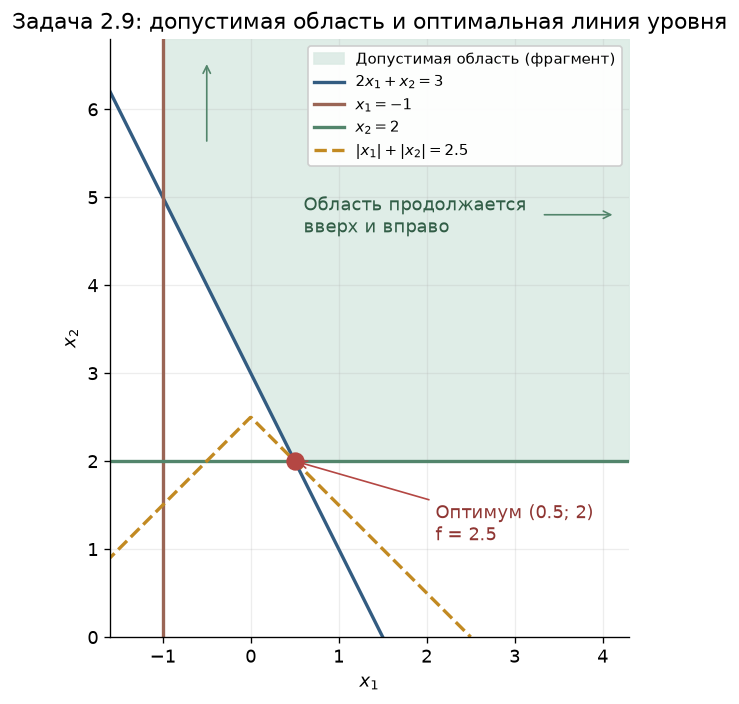

In [12]:
horizontal_29 = np.linspace(-1.6, 4.3, 800)
feasible_horizontal_29 = np.linspace(-1, 4.3, 700)
lower_boundary_29 = np.maximum(2, 3 - 2 * feasible_horizontal_29)
level_horizontal_29 = np.linspace(-2.5, 2.5, 500)

figure_29, axis_29 = plt.subplots(figsize=(9, 6))
axis_29.fill_between(
    feasible_horizontal_29,
    lower_boundary_29,
    6.8,
    color="#DCEBE5",
    alpha=0.9,
    label="Допустимая область (фрагмент)",
)
axis_29.plot(horizontal_29, 3 - 2 * horizontal_29, color="#335C81", label=r"$2x_1+x_2=3$")
axis_29.axvline(-1, color="#9A6555", label=r"$x_1=-1$")
axis_29.axhline(2, color="#52856B", label=r"$x_2=2$")
axis_29.plot(
    level_horizontal_29,
    2.5 - np.abs(level_horizontal_29),
    color="#C28A22",
    linestyle="--",
    linewidth=2,
    label=r"$|x_1|+|x_2|=2.5$",
)
axis_29.scatter(
    [optimal_x1_29],
    [optimal_x2_29],
    color="#B44743",
    s=100,
    zorder=5,
)
axis_29.annotate(
    "Оптимум (0.5; 2)\nf = 2.5",
    xy=(optimal_x1_29, optimal_x2_29),
    xytext=(2.1, 1.1),
    arrowprops={"arrowstyle": "->", "color": "#B44743"},
    color="#8F3633",
)
axis_29.text(0.6, 4.6, "Область продолжается\nвверх и вправо", color="#315D46")
axis_29.annotate(
    "",
    xy=(-0.5, 6.55),
    xytext=(-0.5, 5.6),
    arrowprops={"arrowstyle": "->", "color": "#52856B"},
)
axis_29.annotate(
    "",
    xy=(4.15, 4.8),
    xytext=(3.3, 4.8),
    arrowprops={"arrowstyle": "->", "color": "#52856B"},
)
axis_29.set(
    xlim=(-1.6, 4.3),
    ylim=(0, 6.8),
    xlabel=r"$x_1$",
    ylabel=r"$x_2$",
    title="Задача 2.9: допустимая область и оптимальная линия уровня",
)
axis_29.set_aspect("equal", adjustable="box")
axis_29.legend(loc="upper right", fontsize=9, framealpha=0.95)
figure_29.tight_layout()
plt.show()

### Ответ

**(a)** На графике показана неограниченная допустимая область. Единственное оптимальное решение: **$x_1^*=1/2$, $x_2^*=2$**, минимальное значение **$f^*=5/2$**.

**(b)** Эквивалентная модель ЛО: минимизировать $u_1+u_2$ при $u_i\ge x_i$, $u_i\ge-x_i$, $u_i\ge0$, $i=1,2$, и исходных ограничениях $2x_1+x_2\ge3$, $x_1\ge-1$, $x_2\ge2$.

<a id="task-210"></a>

## Задача 2.10

### Условие

Рассмотрим следующую задачу оптимизации:

$$
\begin{aligned}
\max\quad &\frac{5x_1+6x_2}{2x_2+7}\\
\text{п.р.}\quad &2x_1+3x_2\le6\\
&2x_1+x_2\le3\\
&x_1,x_2\ge0.
\end{aligned}
$$

Сформулируйте ее как задачу ЛО и решите ее.

### Дано

- Целевая функция: $f(x)=(5x_1+6x_2)/(2x_2+7)\to\max$.
- Ограничения: $2x_1+3x_2\le6$, $2x_1+x_2\le3$, $x_1,x_2\ge0$.
- Переменные непрерывные; знаменатель на допустимом множестве положителен: $2x_2+7\ge7$.

### Математическая модель

Используем преобразование Чарнса—Купера из раздела о дробной целевой функции:

$$t=\frac{1}{2x_2+7}>0,\qquad y_1=tx_1,\qquad y_2=tx_2.$$

Умножение ограничений на $t>0$ сохраняет знаки неравенств, а нормировка знаменателя даёт $2y_2+7t=1$. Получаем модель ЛО:

$$
\begin{aligned}
\max\quad &5y_1+6y_2,\\
\text{при}\quad &2y_1+3y_2\le6t,\\
&2y_1+y_2\le3t,\\
&2y_2+7t=1,\\
&y_1,y_2,t\ge0.
\end{aligned}
$$

Строгое неравенство $t>0$ не нужно отдельно задавать решателю: при $t=0$ первое ограничение и неотрицательность вынуждают $y_1=y_2=0$, что противоречит нормировке. Поэтому восстановление $x_1=y_1/t$, $x_2=y_2/t$ корректно для любого допустимого решения новой модели.

### Найти

Эквивалентную задачу ЛО и оптимальное решение исходной задачи.

### Решение

In [13]:
model_210 = pyo.ConcreteModel()
model_210.y1 = pyo.Var(domain=pyo.NonNegativeReals)
model_210.y2 = pyo.Var(domain=pyo.NonNegativeReals)
model_210.scale = pyo.Var(domain=pyo.NonNegativeReals)
model_210.first_bound = pyo.Constraint(
    expr=2 * model_210.y1 + 3 * model_210.y2 <= 6 * model_210.scale
)
model_210.second_bound = pyo.Constraint(
    expr=2 * model_210.y1 + model_210.y2 <= 3 * model_210.scale
)
model_210.normalization = pyo.Constraint(
    expr=2 * model_210.y2 + 7 * model_210.scale == 1
)
model_210.linear_objective = pyo.Objective(
    expr=5 * model_210.y1 + 6 * model_210.y2,
    sense=pyo.maximize,
)
solve_model(model_210)

scale_210 = pyo.value(model_210.scale)
original_x1_210 = pyo.value(model_210.y1) / scale_210
original_x2_210 = pyo.value(model_210.y2) / scale_210
original_objective_210 = (
    (5 * original_x1_210 + 6 * original_x2_210) / (2 * original_x2_210 + 7)
)
display(
    pd.DataFrame(
        {
            "Переменная": ["y₁", "y₂", "t", "x₁ = y₁/t", "x₂ = y₂/t"],
            "Оптимальное значение": [
                pyo.value(model_210.y1),
                pyo.value(model_210.y2),
                scale_210,
                original_x1_210,
                original_x2_210,
            ],
        }
    )
)
display(
    pd.DataFrame(
        {
            "Ограничение исходной задачи": ["2x₁ + 3x₂ ≤ 6", "2x₁ + x₂ ≤ 3"],
            "Левая часть": [
                2 * original_x1_210 + 3 * original_x2_210,
                2 * original_x1_210 + original_x2_210,
            ],
            "Правая часть": [6, 3],
        }
    )
)
print(f"Значение цели ЛП: {pyo.value(model_210.linear_objective):.6f}")
print(f"Значение исходной дробной цели: {original_objective_210:.6f}")

,Переменная,Оптимальное значение
0,y₁,0.0750
1,y₂,0.1500
2,t,0.1000
3,x₁ = y₁/t,0.7500
4,x₂ = y₂/t,1.5000


,Ограничение исходной задачи,Левая часть,Правая часть
0,2x₁ + 3x₂ ≤ 6,6.0000,6
1,2x₁ + x₂ ≤ 3,3.0000,3


Значение цели ЛП: 1.275000
Значение исходной дробной цели: 1.275000


### Ответ

Эквивалентная задача ЛО:

$$
\max(5y_1+6y_2)\quad\text{при}\quad
2y_1+3y_2\le6t,\quad2y_1+y_2\le3t,\quad
2y_2+7t=1,\quad y_1,y_2,t\ge0.
$$

Её оптимальное решение: $y_1^*=3/40$, $y_2^*=3/20$, $t^*=1/10$. После обратной замены получаем **$x_1^*=3/4$, $x_2^*=3/2$** и **$f^*=51/40=1.275$**.